Step 1: Import Required Libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


Step 2: Define Input and Output for AND Gate

In [ ]:
# Input vectors for AND gate
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

# Expected outputs
y = np.array([0, 0, 0, 1])


In [ ]:
# Number of features = 2 (x1, x2)
input_dim = 2
# Initialize weights and bias
weights = np.zeros(input_dim)
bias = 0.0
# Learning rate and number of epochs
lr = 0.1
epochs = 10


Step 3: Initialize Perceptron Parameters

In [ ]:
# Step 3: Initialize Perceptron
input_dim = 2
weights = np.zeros(input_dim)
bias = 0.0
lr = 0.1
epochs = 10


Step 4: Define the Activation Function (Step Function)

In [ ]:
# Step 4: Define Activation Function
def activation(z):`
    return 1 if z >= 0 else 0


Step 5: Train the Perceptron

In [ ]:
# Step 5: Train the Perceptron
print("Training the Perceptron...\n")
for epoch in range(epochs):
    print(f"Epoch {epoch+1}/{epochs}")
    for i in range(len(X)):
        x_i = X[i]
        target = y[i]

        # Linear output
        linear_output = np.dot(x_i, weights) + bias
        y_pred = activation(linear_output)
        error = target - y_pred

        # Update weights and bias if there's an error
        if error != 0:
            weights += lr * error * x_i
            bias += lr * error

        print(f" Input: {x_i}, Target: {target}, Prediction: {y_pred}, Error: {error}")
        print(f" --> Updated Weights: {weights}, Bias: {bias}\n")


Training the Perceptron...

Epoch 1/10
 Input: [0 0], Target: 0, Prediction: 1, Error: -1
 --> Updated Weights: [0. 0.], Bias: -0.1

 Input: [0 1], Target: 0, Prediction: 0, Error: 0
 --> Updated Weights: [0. 0.], Bias: -0.1

 Input: [1 0], Target: 0, Prediction: 0, Error: 0
 --> Updated Weights: [0. 0.], Bias: -0.1

 Input: [1 1], Target: 1, Prediction: 0, Error: 1
 --> Updated Weights: [0.1 0.1], Bias: 0.0

Epoch 2/10
 Input: [0 0], Target: 0, Prediction: 1, Error: -1
 --> Updated Weights: [0.1 0.1], Bias: -0.1

 Input: [0 1], Target: 0, Prediction: 1, Error: -1
 --> Updated Weights: [0.1 0. ], Bias: -0.2

 Input: [1 0], Target: 0, Prediction: 0, Error: 0
 --> Updated Weights: [0.1 0. ], Bias: -0.2

 Input: [1 1], Target: 1, Prediction: 0, Error: 1
 --> Updated Weights: [0.2 0.1], Bias: -0.1

Epoch 3/10
 Input: [0 0], Target: 0, Prediction: 0, Error: 0
 --> Updated Weights: [0.2 0.1], Bias: -0.1

 Input: [0 1], Target: 0, Prediction: 1, Error: -1
 --> Updated Weights: [0.2 0. ], Bias

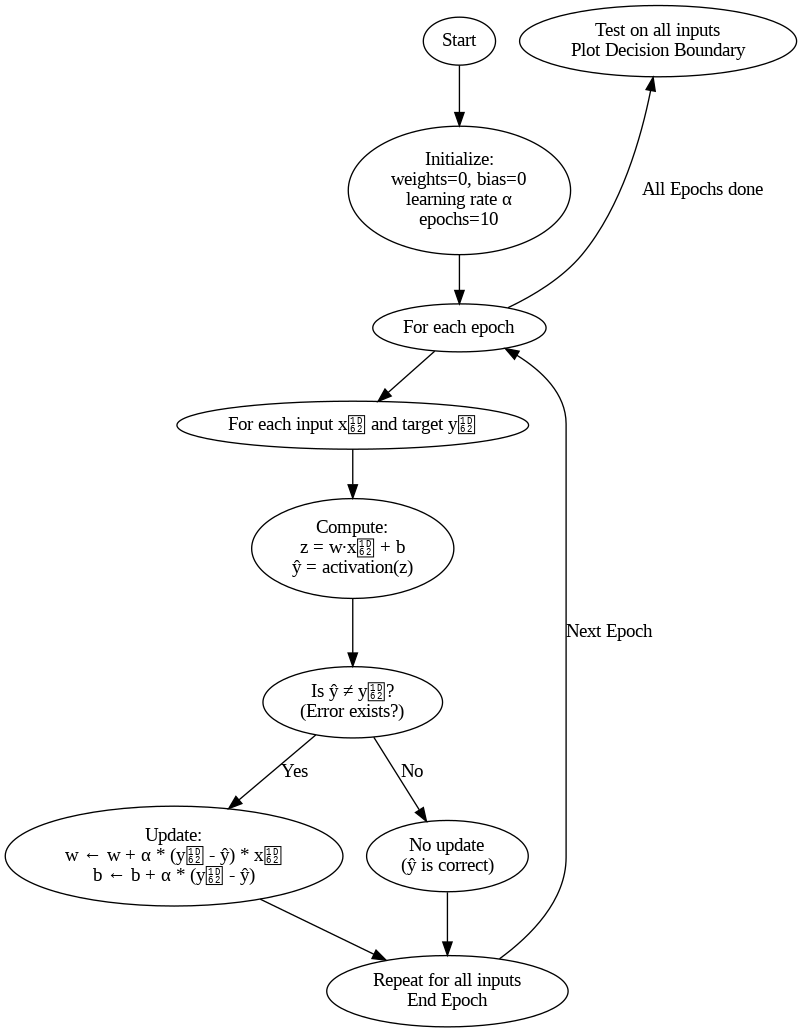

Step 6: Test Final Model

In [ ]:
# Step 6: Final Predictions
print("Testing on all inputs:\n")
final_predictions = []

for i in range(len(X)):
    linear_output = np.dot(X[i], weights) + bias
    y_pred = activation(linear_output)
    final_predictions.append(y_pred)
    print(f"Input: {X[i]}, Predicted: {y_pred}, Actual: {y[i]}")


Testing on all inputs:

Input: [0 0], Predicted: 0, Actual: 0
Input: [0 1], Predicted: 0, Actual: 0
Input: [1 0], Predicted: 0, Actual: 0
Input: [1 1], Predicted: 1, Actual: 1


Step 7: Plot the Decision Boundary

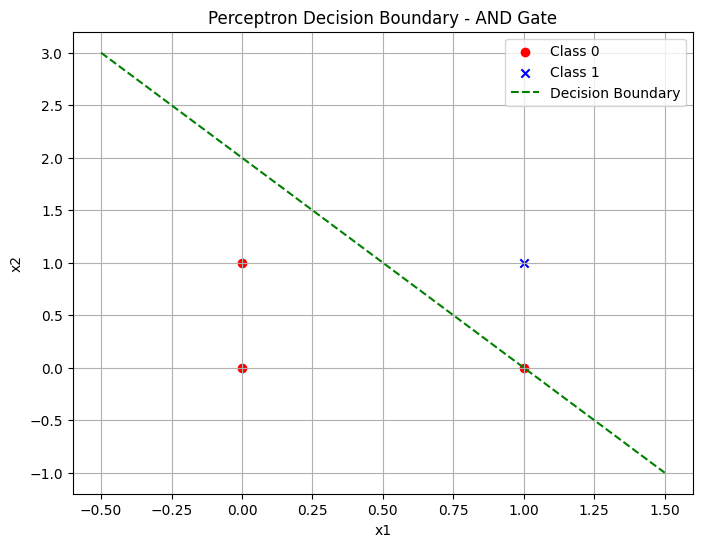

In [ ]:
# Step 7: Plot Decision Boundary
x1 = np.linspace(-0.5, 1.5, 10)
x2 = -(weights[0] * x1 + bias) / weights[1] if weights[1] != 0 else np.zeros_like(x1)

plt.figure(figsize=(8,6))
for i in range(len(X)):
    if y[i] == 0:
        plt.scatter(X[i][0], X[i][1], color='red', marker='o', label='Class 0' if i==0 else "")
    else:
        plt.scatter(X[i][0], X[i][1], color='blue', marker='x', label='Class 1' if i==3 else "")

plt.plot(x1, x2, label='Decision Boundary', linestyle='--', color='green')
plt.title("Perceptron Decision Boundary - AND Gate")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid(True)
plt.legend()
plt.show()


/tmp/ipython-input-9-82156682.py:61: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  axs[1, 0].scatter(X[i][0], X[i][1], c=colors[i], marker=markers[i], s=100, edgecolors='k')


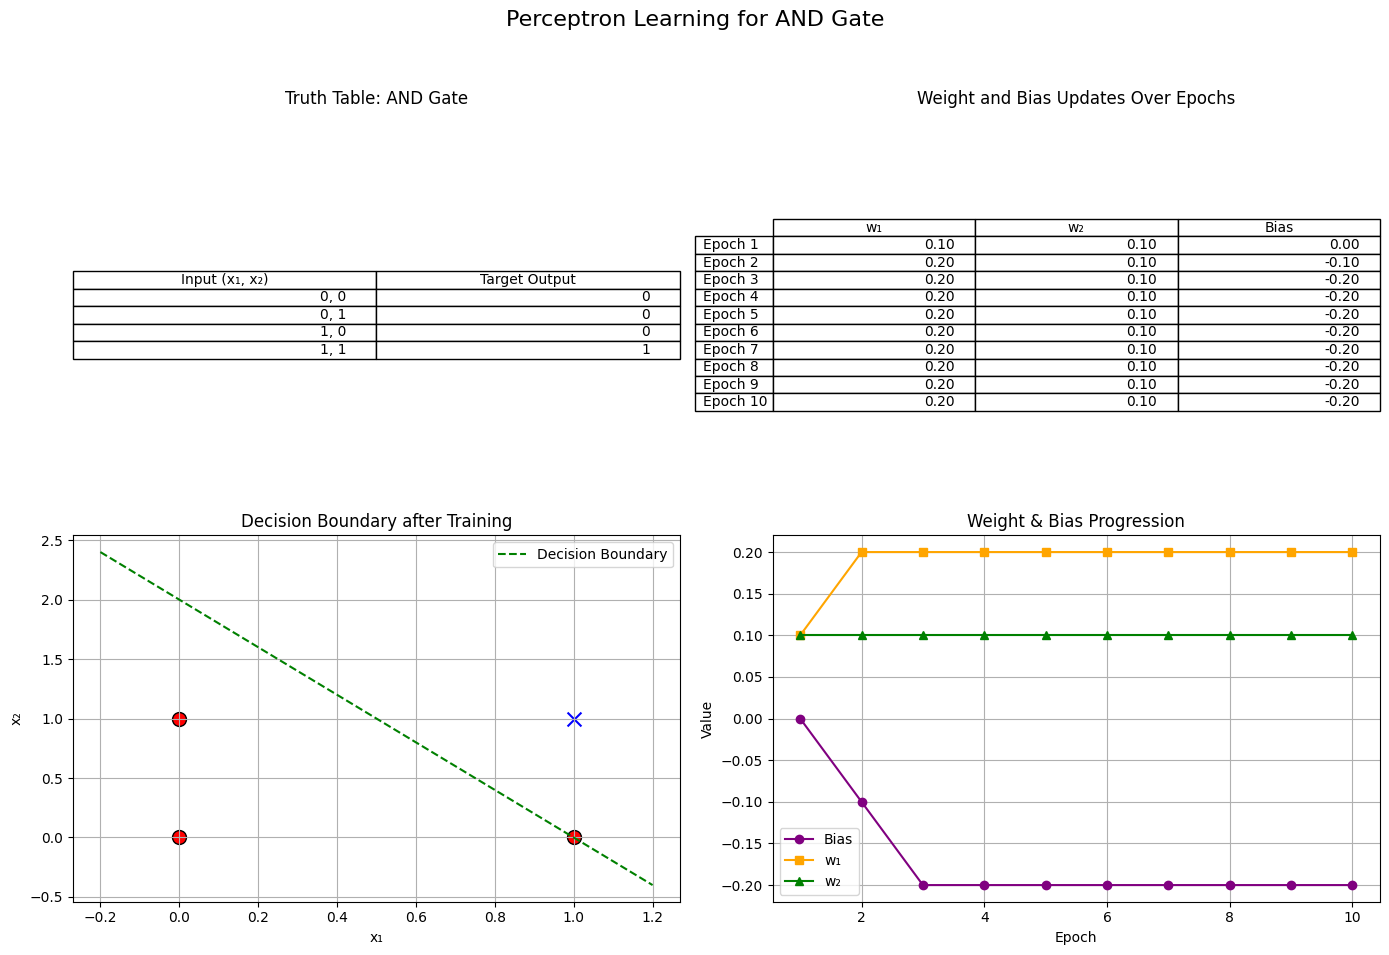

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# AND Gate Data
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])
y = np.array([0, 0, 0, 1])

# Perceptron Parameters
weights = np.zeros(2)
bias = 0.0
lr = 0.1
epochs = 10

# Store weights and bias after each epoch
history = []

# Activation function
def activation(z):
    return 1 if z >= 0 else 0

# Training with tracking
for epoch in range(epochs):
    for i in range(len(X)):
        x_i = X[i]
        target = y[i]
        linear_output = np.dot(x_i, weights) + bias
        y_pred = activation(linear_output)
        error = target - y_pred
        if error != 0:
            weights += lr * error * x_i
            bias += lr * error
    history.append((weights.copy(), bias))

# Set up subplot grid
fig, axs = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Perceptron Learning for AND Gate', fontsize=16)

# 1. Top-left: Input/Output Table
axs[0, 0].axis('off')
table_data = [[f"{x[0]}, {x[1]}", y[i]] for i, x in enumerate(X)]
column_labels = ["Input (x₁, x₂)", "Target Output"]
axs[0, 0].table(cellText=table_data, colLabels=column_labels, loc='center')
axs[0, 0].set_title("Truth Table: AND Gate", pad=20)

# 2. Top-right: Weight & Bias Update Log
axs[0, 1].axis('off')
rows = [f"Epoch {i+1}" for i in range(epochs)]
w_log = [[f"{w[0]:.2f}", f"{w[1]:.2f}", f"{b:.2f}"] for w, b in history]
axs[0, 1].table(cellText=w_log, rowLabels=rows, colLabels=["w₁", "w₂", "Bias"], loc='center')
axs[0, 1].set_title("Weight and Bias Updates Over Epochs", pad=20)

# 3. Bottom-left: Decision Boundary and Inputs
colors = ['red' if val == 0 else 'blue' for val in y]
markers = ['o' if val == 0 else 'x' for val in y]
for i in range(len(X)):
    axs[1, 0].scatter(X[i][0], X[i][1], c=colors[i], marker=markers[i], s=100, edgecolors='k')

# Plot final decision boundary
final_w, final_b = history[-1]
x_vals = np.linspace(-0.2, 1.2, 10)
y_vals = -(final_w[0] * x_vals + final_b) / final_w[1]
axs[1, 0].plot(x_vals, y_vals, '--', color='green', label='Decision Boundary')
axs[1, 0].set_title("Decision Boundary after Training")
axs[1, 0].set_xlabel("x₁")
axs[1, 0].set_ylabel("x₂")
axs[1, 0].grid(True)
axs[1, 0].legend()

# 4. Bottom-right: Epoch Timeline
axs[1, 1].plot(range(1, epochs+1), [b for _, b in history], label='Bias', marker='o', color='purple')
axs[1, 1].plot(range(1, epochs+1), [w[0] for w, _ in history], label='w₁', marker='s', color='orange')
axs[1, 1].plot(range(1, epochs+1), [w[1] for w, _ in history], label='w₂', marker='^', color='green')
axs[1, 1].set_title("Weight & Bias Progression")
axs[1, 1].set_xlabel("Epoch")
axs[1, 1].set_ylabel("Value")
axs[1, 1].grid(True)
axs[1, 1].legend()

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


In [ ]:
!pip install graphviz


In [ ]:
from graphviz import Digraph

# Create the flowchart
dot = Digraph(comment='Perceptron Training Flowchart', format='png')

# Step 1: Start
dot.node('A', 'Start')

# Step 2: Initialize parameters
dot.node('B', 'Initialize:\nweights=0, bias=0\nlearning rate α\nepochs=10')

# Step 3: Loop over epochs
dot.node('C', 'For each epoch')

# Step 4: Loop over inputs
dot.node('D', 'For each input xᵢ and target yᵢ')

# Step 5: Compute output
dot.node('E', 'Compute:\nz = w·xᵢ + b\nŷ = activation(z)')

# Step 6: Check prediction
dot.node('F', 'Is ŷ ≠ yᵢ?\n(Error exists?)')

# Step 7: Update rule
dot.node('G', 'Update:\nw ← w + α * (yᵢ - ŷ) * xᵢ\nb ← b + α * (yᵢ - ŷ)')

# Step 8: No update
dot.node('H', 'No update\n(ŷ is correct)')

# Step 9: End epoch
dot.node('I', 'Repeat for all inputs\nEnd Epoch')

# Step 10: End
dot.node('J', 'Test on all inputs\nPlot Decision Boundary')

# Define edges
dot.edges(['AB', 'BC', 'CD', 'DE'])
dot.edge('E', 'F')
dot.edge('F', 'G', label='Yes')
dot.edge('F', 'H', label='No')
dot.edge('G', 'I')
dot.edge('H', 'I')
dot.edge('I', 'C', label='Next Epoch', constraint='true')
dot.edge('C', 'J', label='All Epochs done', constraint='false')

# Render and display
dot.render('perceptron_training_flowchart', view=True)


'perceptron_training_flowchart.png'